# Graphics

## Plots

To plot an orbit, simply use the [`plot()`](orbit.Orbit.plot) method and pass in the starting and ending Mino time.

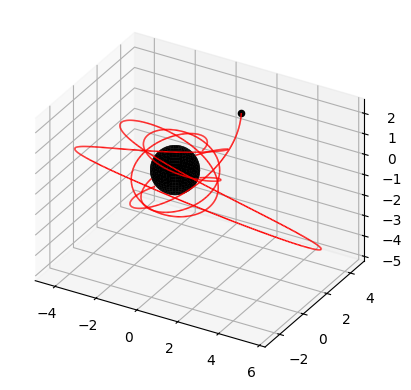

In [1]:
import kerrgeopy as kg
from math import pi, cos

orbit = kg.StableOrbit(0.998,3,0.6,cos(pi/4))
fig, ax = orbit.plot(0,10)

Use the `initial_phases` option to set the initial phases $(q_{t_0},q_{r_0},q_{\theta_0},q_{\phi_0})$ of the trajectory. For example, set $q_{r_0} = \pi$ to start the orbit from $r_{\text{max}}$.

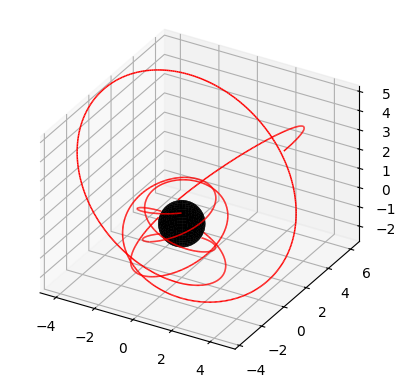

In [2]:
fig, ax = orbit.plot(0,10, initial_phases=(0,pi,0,0))

Use the `elevation` and `azimuth` options to set the viewing angles as defined by [matplotlib](https://matplotlib.org/stable/api/toolkits/mplot3d/view_angles.html). To plot the orbit with a decaying tail, use the `tau` option to set the time constant in units of Mino time for the exponential decay in the linewidth of the tail. Use `lw` to adjust the initial linewidth.

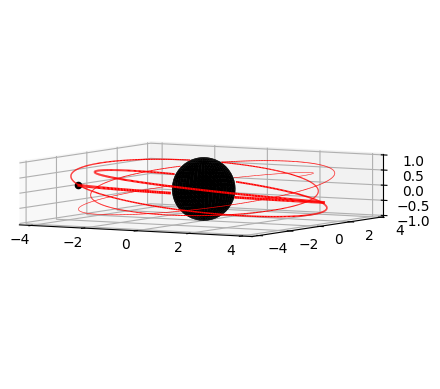

In [3]:
orbit = kg.StableOrbit(0.999,4,0.1,cos(pi/20))
fig, ax = orbit.plot(0,10, elevation=5, lw=2, tau=5)

The `grid` and `axes` options can be used to turn off the visibility of the grid and axes.

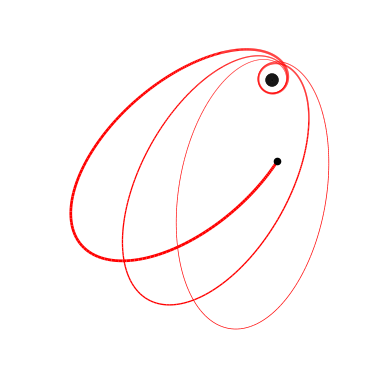

In [4]:
orbit = kg.StableOrbit(0.999,4,0.9,cos(0))
fig, ax = orbit.plot(0,10, elevation=90, azimuth=0, grid=False, axes=False, lw=2, tau=5)

## Animations

To animate an orbit, use the [`animate()`](orbit.Orbit.animate) method by passing in a filename to save the animation to, along with a starting and ending Mino time. Note that this method requires ffmpeg to be installed and may take several minutes to run depending on the length of the animation.

In [ ]:
orbit = kg.StableOrbit(0.998,3,0.6,cos(pi/4))
orbit.animate("animation1.mp4",0,10)

<video width="75%" controls autoplay loop>
  <source src="https://cdn.jsdelivr.net/gh/BlackHolePerturbationToolkit/KerrGeoPy@main/docs/source/notebooks/animation1.mp4" type="video/mp4">
  <p>

  [](animation1.mp4)
  
  </p>
</video>

All of the options available when plotting are also available within the [`animate()`](stable.StableOrbit.animate) method. It is also possible to control the motion of the camera by passing in functions to set the azimuth and elevation angle in degrees as a function of Mino time.

In [ ]:
from math import sin

orbit = kg.StableOrbit(0.998,2.1,0.8,cos(pi/20))
orbit.animate("animation2.mp4",0,20,
             elevation_pan = lambda x: 10*sin(2*pi*x/20),
             azimuthal_pan = lambda x: 360*x/20)

<video width="75%" controls autoplay loop>
  <source src="https://cdn.jsdelivr.net/gh/BlackHolePerturbationToolkit/KerrGeoPy@main/docs/source/notebooks/animation2.mp4" type="video/mp4">
  <p>

  [](animation2.mp4)
  
  </p>
</video>

Use the `background_color` option to change the background color of the animation. If necesssary, use `plt.style.use('dark_background')` or `with plt.style.context('dark_background'):` to change the color of the grid and axes to white.

In [ ]:
import matplotlib.pyplot as plt

orbit = kg.StableOrbit(0.999,4,0.1,cos(pi/20))
with plt.style.context('dark_background'):
    orbit.animate("animation3.mp4",0,10, background_color="black", elevation=10)

<video width="75%" controls autoplay loop>
  <source src="https://cdn.jsdelivr.net/gh/BlackHolePerturbationToolkit/KerrGeoPy@main/docs/source/notebooks/animation3.mp4" type="video/mp4">
  <p>

  [](animation3.mp4)
  
  </p>
</video>

Similar to `elevation_pan` and `azimuthal_pan`, `roll` can be used to set the roll angle of the camera as a function of Mino time.

In [ ]:
from math import exp

orbit = kg.StableOrbit(0.999,3,0.1,cos(pi/20))
orbit.animate("animation4.mp4", 
              elevation_pan = lambda x: 180*x/10,
              roll = lambda x: 180/(1+exp(10-2*x)),
            )

<video width="75%" controls autoplay loop>
  <source src="https://cdn.jsdelivr.net/gh/BlackHolePerturbationToolkit/KerrGeoPy@main/docs/source/notebooks/animation4.mp4" type="video/mp4">
  <p>

  [](animation4.mp4)
  
  </p>
</video>

The primary black hole is always placed in the center of the plot, so the axis limits are symmetric about the origin and are the same along all three axes. To zoom in and out of the orbit, use the `axis_limit` option to set the axis limit as a function of Mino time. Set `plot_components` to `True` in order to plot each of the individual components of the trajectory alongside the orbit itself.

In [ ]:
orbit = kg.StableOrbit(0.998,2.1,0.8,cos(pi/20))
t, r, theta, phi = orbit.trajectory()

with plt.style.context('dark_background'):
    orbit.animate("animation5.mp4",0,30,
                elevation = 10,
                azimuthal_pan = lambda x: 360*x/20,
                axis_limit = lambda x: r(x)+1,
                plot_components=True,
                grid=False,
                background_color="black"
                )

<video width="100%" controls autoplay loop>
  <source src="https://cdn.jsdelivr.net/gh/BlackHolePerturbationToolkit/KerrGeoPy@main/docs/source/notebooks/animation5.mp4" type="video/mp4">
  <p>

  [](animation5.mp4)
  
  </p>
</video>

## Shadow of the Black Hole

Using the [`KerrImage`](images.KerrImage) class, we can generate images of the black hole.

First, create the image and compute the data

In [ ]:
from kerrgeopy import KerrImage
img = KerrImage(0.9, pi/3, (1920, 1080), 40)
img.compute()

The image (including generated data) can be saved with the [`save()`](images.KerrImage.save) method and loaded with the [`from_file()`](images.KerrImage.from_file) method

In [6]:
with open("img.json", "w+") as fp:
    img.save(fp)

In [1]:
with open("img.json", "r") as fp:
    img = KerrImage.from_file(fp)

Using the [`image()`](images.KerrImage.image) method, we can obtain the distorted image of the provided spheremap as a [`PIL.Image`](https://pillow.readthedocs.io/en/stable/reference/Image.html)

In [2]:
from PIL import Image
# image from https://sci.esa.int/s/ApPJaGA
bg = Image.open("skymap.jpg")
bg

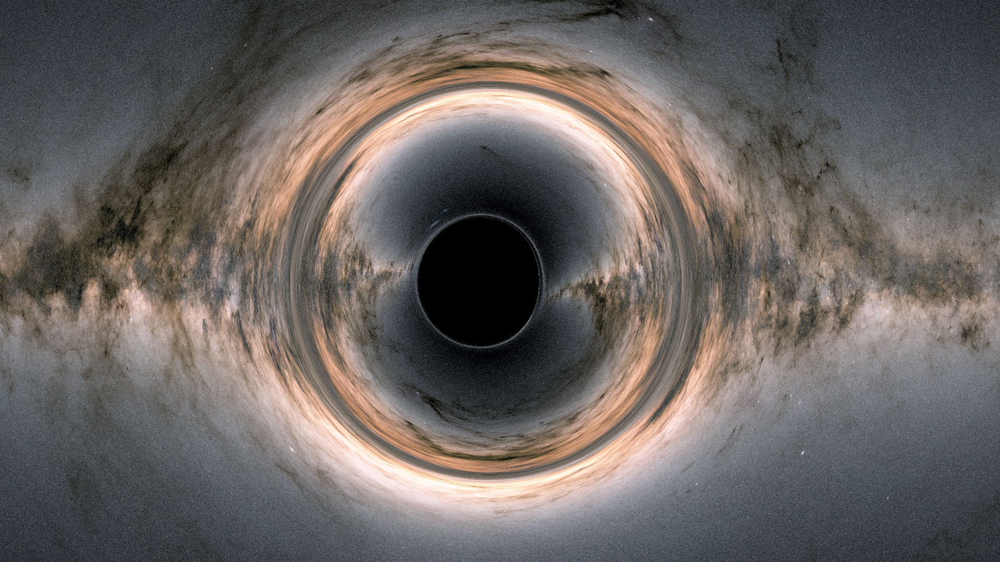

In [3]:
img.image(bg=bg)

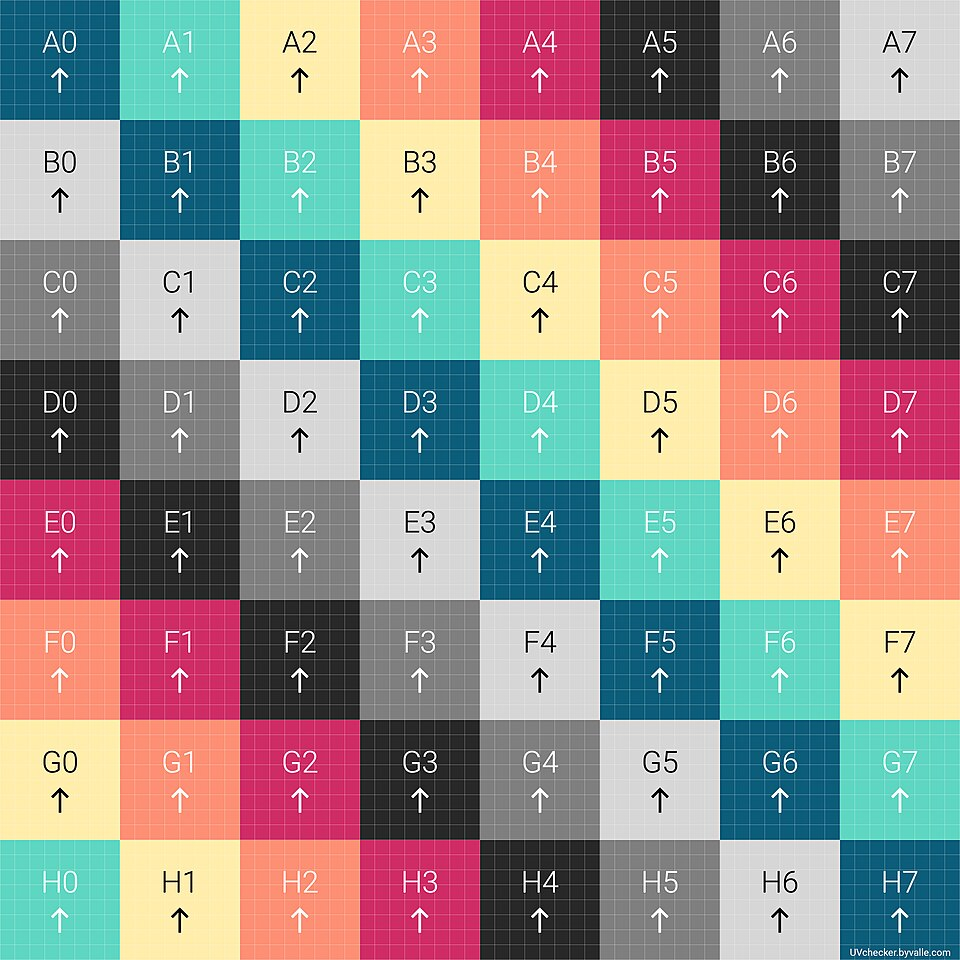

In [ ]:
# image from https://commons.wikimedia.org/wiki/File:UV_checker_Map_byValle.jpg
uv = Image.open("uv.jpg")
uv

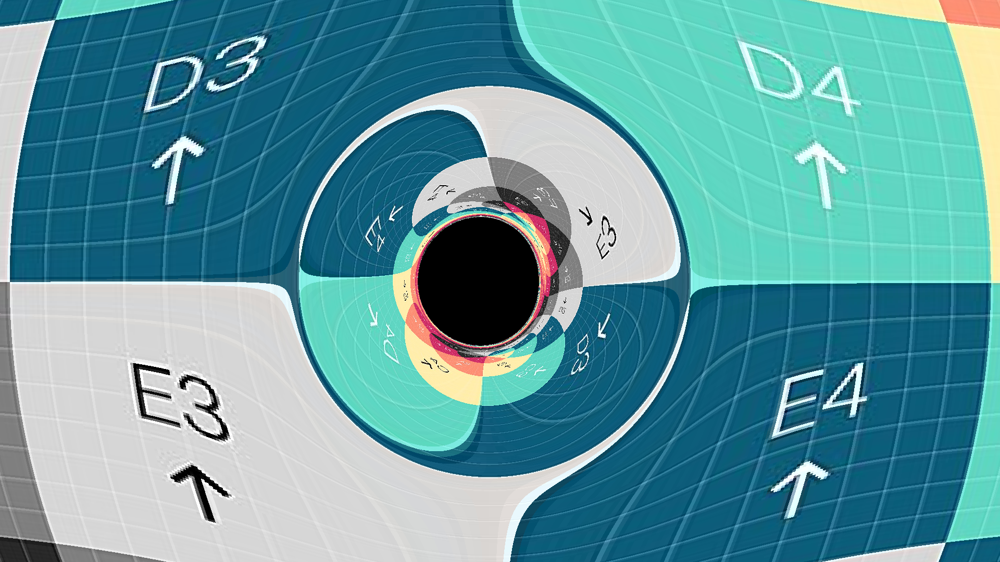

In [ ]:
img.image(bg=uv)

If we don't pass any image for the background, we get a colormap

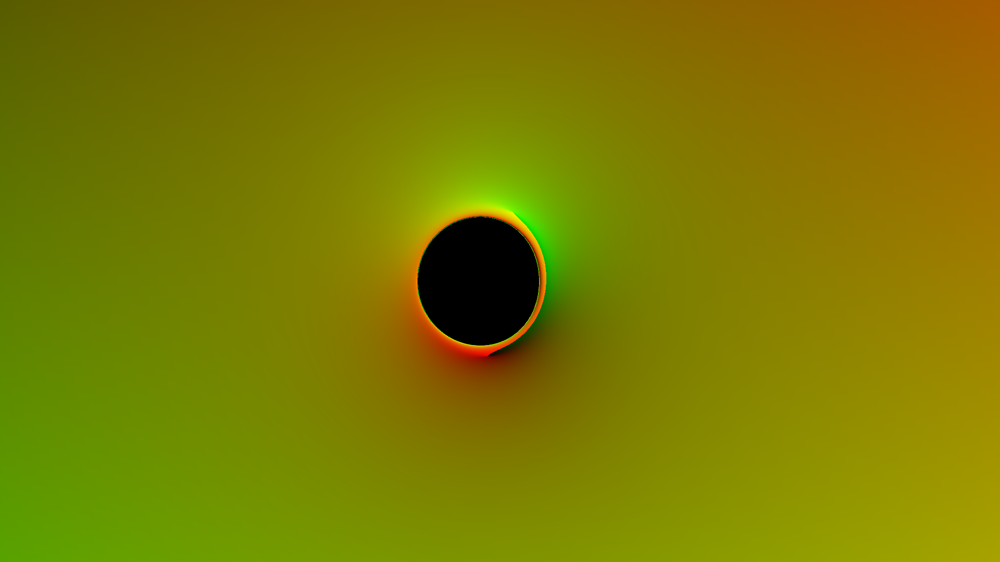

In [ ]:
img.image()

The class also has the [`orbit()`](images.KerrImage.orbit) method that can create an orbiting animation

In [ ]:
img.orbit("orbit.mp4", 10, bg=bg, size=(1280, 720))

<video width="100%" controls autoplay loop>
  <source src="../_downloads/e9649e55f2e4d1e30e20e8388ea6f889/orbit.mp4" type="video/mp4">
  <p>

  [](orbit.mp4)
  
  </p>
</video>